<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




# جلسه ۴ — مقادیر ویژه، بردارهای ویژه و ماتریس‌های معین مثبت
### مبانی ریاضی یادگیری ماشین | بخش دوم: جبر خطی پیشرفته

**اهداف یادگیری این جلسه:**
- فهم شهودی بردار ویژه (eigenvector) و مقدار ویژه (eigenvalue): چرا بعضی جهت‌ها تحت یک تبدیل ماتریسی «فقط کشیده می‌شوند» نه چرخانده؟
- محاسبه‌ی آن‌ها با کد و تجسم هندسی‌شان
- فهم ماتریس معین مثبت (Positive Definite) و ارتباطش با «شکل کاسه‌ای بودن» یک تابع زیان (Loss Function)
- توانایی تشخیص این‌که یک نقطه‌ی بحرانی در بهینه‌سازی، مینیمم واقعی است یا نه — صرفاً از روی علامت مقادیر ویژه

> 📘 **جعبه واژه‌نامه** — هر جا اصطلاح تخصصی جدیدی به‌کار می‌رود، همین‌جا با یک مثال ساده و غیرتخصصی توضیح داده می‌شود. لازم نیست از قبل این کلمات را بلد باشید.

> **پیش‌مطالعه:** فصل ۴ *Mathematics for Machine Learning* (بخش‌های ۴.۱ تا ۴.۳ — Eigenvalues and Eigenvectors) + یادآوری سریع بخش تعامد و تصویر از جلسه‌ی قبل.


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>







# نرم القایی ماتریس (Induced Matrix Norm)

## تعریف

فرض کنید $\|\cdot\|$ یک نرم برداری روی $\mathbb{R}^n$ (یا $\mathbb{C}^n$) باشد. **نرم القایی** (یا نرم عملگری) ماتریس $A \in \mathbb{R}^{m \times n}$ نسبت به این نرم برداری به صورت زیر تعریف می‌شود:

$$\|A\| = \sup_{x \neq 0} \frac{\|Ax\|}{\|x\|} = \max_{\|x\|=1} \|Ax\|$$

یعنی نرم ماتریس برابر است با بیشترین مقداری که ماتریس $A$ می‌تواند نرم یک بردار را «بزرگ» کند.

## ویژگی‌های مهم

1. **سازگاری با نرم برداری:** برای هر بردار $x$ داریم
$$\|Ax\| \le \|A\|\,\|x\|$$

2. **زیرضربی بودن (submultiplicative):**
$$\|AB\| \le \|A\|\,\|B\|$$

3. **نرم ماتریس همانی:** $\|I\| = 1$

4. **خواص نرم:** نامنفی بودن، همگنی ($\|\alpha A\| = |\alpha|\|A\|$) و نامساوی مثلثی ($\|A+B\| \le \|A\|+\|B\|$).

## نرم‌های القایی رایج

| نرم برداری | نرم القایی ماتریس | فرمول |
|---|---|---|
| $\|x\|_1$ | نرم ستونی | $\|A\|_1 = \max_j \sum_i \lvert a_{ij}\rvert$ |
| $\|x\|_\infty$ | نرم سطری | $\|A\|_\infty = \max_i \sum_j \lvert a_{ij}\rvert$ |
| $\|x\|_2$ | نرم طیفی | $\|A\|_2 = \sqrt{\lambda_{\max}(A^TA)} = \sigma_{\max}(A)$ |

## مثال

برای ماتریس
$$A = \begin{pmatrix} 1 & -2 \\ 3 & 4 \end{pmatrix}$$

- $\|A\|_1 = \max(1+3,\ 2+4) = 6$
- $\|A\|_\infty = \max(1+2,\ 3+4) = 7$

## نکته

نرم فروبنیوس $\|A\|_F = \sqrt{\sum_{i,j} |a_{ij}|^2}$ یک نرم ماتریسی زیرضربی است، اما **نرم القایی نیست** (چون برای ماتریس همانی $n\times n$ مقدار آن $\sqrt{n}$ است، نه ۱).

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## 🎯 چالش واقعی این جلسه: چطور گوگل صفحات وب را رتبه‌بندی می‌کند؟

فرض کنید یک وب‌سایت کوچک با ۴ صفحه داریم که به هم لینک می‌دهند. گوگل باید تصمیم بگیرد کدام صفحه «مهم‌تر» است — نه بر اساس محتوا، بلکه صرفاً بر اساس اینکه چند صفحه‌ی مهم دیگر به آن لینک داده‌اند (این ایده‌ی اصلی الگوریتم **PageRank** است، همان الگوریتمی که گوگل را ساخت).

قانون ساده: هر صفحه، «امتیاز اهمیت» خودش را به‌طور مساوی بین صفحاتی که به آن‌ها لینک می‌دهد پخش می‌کند. این کار را بارها و بارها تکرار می‌کنیم. سؤال: آیا امتیازها بالاخره **ثابت** می‌شوند (به یک حالت پایدار می‌رسند)؟ و اگر بله، آن حالت پایدار چیست؟

بیایید عملاً امتحان کنیم.

In [3]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ماتریس لینک: L[i, j] = 1 اگر صفحه j به صفحه i لینک بدهد
# ۴ صفحه: A, B, C, D
#   A -> B, C
#   B -> C
#   C -> A
#   D -> C
pages = ["A", "B", "C", "D"]
L = torch.tensor([
    [0.0, 0.0, 1.0, 0.0],   # به A چه کسانی لینک می‌دهند؟ فقط C
    [1.0, 0.0, 0.0, 0.0],   # به B؟ فقط A
    [1.0, 1.0, 0.0, 1.0],   # به C؟ A, B, D
    [0.0, 0.0, 0.0, 0.0],   # به D؟ هیچکس
])

# نرمال‌سازی ستون‌ها: هر صفحه امتیازش را مساوی بین صفحاتی که به آن‌ها لینک می‌دهد پخش می‌کند
out_degree = L.sum(dim=0)
out_degree[out_degree == 0] = 1  # جلوگیری از تقسیم بر صفر
M = L / out_degree

print("ماتریس انتقال (Transition Matrix):\n", M)


ماتریس انتقال (Transition Matrix):
 tensor([[0.0000, 0.0000, 1.0000, 0.0000],
        [0.5000, 0.0000, 0.0000, 0.0000],
        [0.5000, 1.0000, 0.0000, 1.0000],
        [0.0000, 0.0000, 0.0000, 0.0000]])


In [4]:
# شروع با امتیاز مساوی برای همه‌ی صفحات و تکرار قانون پخش امتیاز
score = torch.tensor([0.25, 0.25, 0.25, 0.25])

history = [score.clone()]
for step in range(30):
    score = M @ score
    history.append(score.clone())

for step, s in enumerate(history):
    if step % 3 == 0 or step == len(history) - 1:
        print(f"تکرار {step:2d}: " + "  ".join(f"{p}={v:.3f}" for p, v in zip(pages, s.tolist())))


تکرار  0: A=0.250  B=0.250  C=0.250  D=0.250
تکرار  3: A=0.250  B=0.312  C=0.438  D=0.000
تکرار  6: A=0.344  B=0.219  C=0.438  D=0.000
تکرار  9: A=0.391  B=0.195  C=0.414  D=0.000
تکرار 12: A=0.402  B=0.195  C=0.402  D=0.000
تکرار 15: A=0.402  B=0.198  C=0.399  D=0.000
تکرار 18: A=0.401  B=0.200  C=0.399  D=0.000
تکرار 21: A=0.400  B=0.200  C=0.400  D=0.000
تکرار 24: A=0.400  B=0.200  C=0.400  D=0.000
تکرار 27: A=0.400  B=0.200  C=0.400  D=0.000
تکرار 30: A=0.400  B=0.200  C=0.400  D=0.000


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>


می بینید که بعد از چند تکرار، امتیازها دیگر تغییر نمی‌کنند و به یک بردار ثابت می‌رسند!
این بردار ثابت دقیقاً یک **بردار ویژه** ماتریس $M$ است با **مقدار ویژه** برابر با ۱:

$$
M v = 1 \cdot v
$$

یعنی وقتی $M$ را روی این بردار خاص اعمال می‌کنیم، بردار «همان بردار» باقی می‌ماند (فقط در عدد ۱ ضرب شده، پس اصلاً تغییر نمی‌کند). به همین دلیل این وضعیت «پایدار» است. حالا بیایید مفهوم بردار ویژه را دقیق‌تر و از پایه بررسی کنیم.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>





## بخش ۱: بردار ویژه و مقدار ویژه چیستند؟

📘 وقتی یک ماتریس $A$ را در یک بردار $x$ ضرب می‌کنیم، معمولاً هم **جهت** بردار عوض می‌شود هم **طولش**. اما برای بعضی بردارهای خاص، تبدیل $A$ فقط طول را عوض می‌کند و جهت را دست‌نخورده می‌گذارد (یا دقیقاً معکوس می‌کند). به این بردارهای خاص **بردار ویژه (eigenvector)** آن ماتریس می‌گویند، و عددی که طول را در آن ضرب می‌کند را **مقدار ویژه (eigenvalue)** می‌نامند:

$$
A v = \lambda v
$$

($v$: بردار ویژه، $\lambda$: مقدار ویژه‌ی متناظر با آن)


In [5]:
A = torch.tensor([[2.0, 1.0],
                   [1.0, 2.0]])

eigvals, eigvecs = torch.linalg.eig(A)
print(eigvals)
print(eigvecs)

tensor([3.+0.j, 1.+0.j])
tensor([[ 0.7071+0.j, -0.7071+0.j],
        [ 0.7071+0.j,  0.7071+0.j]])


In [6]:
A = torch.tensor([[1.0, 0.0],
                   [0.0, 1.0]])

eigvals, eigvecs = torch.linalg.eig(A)
print(eigvals)
print(eigvecs)

tensor([1.+0.j, 1.+0.j])
tensor([[1.+0.j, 0.+0.j],
        [0.+0.j, 1.+0.j]])


In [7]:
A = torch.tensor([[2.0, 1.0],
                   [1.0, 2.0]])

eigvals, eigvecs = torch.linalg.eig(A)
eigvals = eigvals.real
eigvecs = eigvecs.real

print("مقادیر ویژه:", eigvals.tolist())
print("بردارهای ویژه (هر ستون یک بردار ویژه است):\n", eigvecs)


مقادیر ویژه: [3.0, 1.0]
بردارهای ویژه (هر ستون یک بردار ویژه است):
 tensor([[ 0.7071, -0.7071],
        [ 0.7071,  0.7071]])


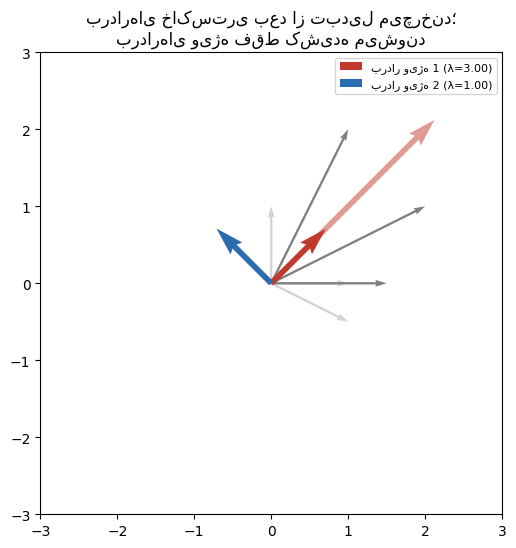

In [8]:
# تجسم: اعمال A روی چند بردار دلخواه در مقابل اعمال آن روی بردارهای ویژه
fig, ax = plt.subplots(figsize=(6, 6))
origin = np.array([0, 0])

# چند بردار دلخواه (غیر ویژه) — رنگ خاکستری: بعد از تبدیل می‌چرخند
random_vecs = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, -0.5]])
for v in random_vecs:
    tv = A @ v
    ax.quiver(*origin, *v.numpy(), angles='xy', scale_units='xy', scale=1,
               color="lightgray", width=0.005)
    ax.quiver(*origin, *tv.numpy(), angles='xy', scale_units='xy', scale=1,
               color="gray", width=0.005)

# بردارهای ویژه — رنگی: بعد از تبدیل فقط کشیده می‌شوند، نمی‌چرخند
colors = ["#c0392b", "#2b6cb0"]
for i in range(2):
    v = eigvecs[:, i]
    tv = A @ v
    ax.quiver(*origin, *v.numpy(), angles='xy', scale_units='xy', scale=1,
               color=colors[i], width=0.012, label=f"بردار ویژه {i+1} (λ={eigvals[i]:.2f})")
    ax.quiver(*origin, *tv.numpy(), angles='xy', scale_units='xy', scale=1,
               color=colors[i], width=0.012, alpha=0.5)

ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
ax.set_aspect("equal")
ax.legend(fontsize=8)
ax.set_title("بردارهای خاکستری بعد از تبدیل می‌چرخند؛\nبردارهای ویژه فقط کشیده می‌شوند")
plt.show()


<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>



### 🗣️ بحث دو‌نفره (Think–Pair–Share) — ۲ دقیقه
در چالش PageRank بالا، مقدار ویژه‌ی متناظر با آن بردار پایدار دقیقاً ۱ بود. با نفر کناری‌تان حدس بزنید: اگر مقدار ویژه به‌جای ۱، عدد ۰.۵ بود، فرایند تکرار به کجا می‌رسید؟ اگر ۲ بود چطور؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




### ✅  اگر مقدار ویژه ۰.۵ یا ۲ بود چه می‌شد؟

یادتان باشد چرا اصلاً «پایدار» شد: چون $Mv = 1 \cdot v$، یعنی هر بار که $M$ را دوباره اعمال می‌کردیم، بردار امتیاز **دقیقاً همان‌جا می‌ماند**. حالا فرض کنیم به‌جای بردار پایدار واقعی، یک بردار ویژه‌ی فرضی $v$ داشتیم با مقدار ویژه‌ی $\lambda$. بعد از $t$ بار تکرار:

$$
\underbrace{M(M(\cdots M}_{t \text{ بار}}v)) = \lambda^t v
$$

یعنی شکل بردار (نسبت امتیاز صفحات به هم) دست‌نخورده می‌ماند، ولی **اندازه‌ی کلی‌اش** در $\lambda^t$ ضرب می‌شود. حالا دو حالت:

- **اگر $\lambda = 0.5$ (یعنی $|\lambda| < 1$):** چون $0.5^t$ با افزایش $t$ به سمت صفر می‌رود، امتیاز همه‌ی صفحات رفته‌رفته **کوچک و کوچک‌تر** می‌شود و در نهایت عملاً همه به صفر می‌رسند. فرایند «ناپدید» می‌شود — دیگر هیچ امتیاز معناداری برای مقایسه‌ی اهمیت صفحات نمی‌ماند.
- **اگر $\lambda = 2$ (یعنی $|\lambda| > 1$):** چون $2^t$ با افزایش $t$ بی‌نهایت بزرگ می‌شود، امتیاز صفحات **منفجر** می‌شود و به سمت بی‌نهایت می‌رود. فرایند هیچ‌وقت به حالت «ثابت» نمی‌رسد.
- **فقط $\lambda = 1$** باعث می‌شود $\lambda^t = 1$ برای همیشه بماند — یعنی تنها همین مقدار ویژه، بردار امتیاز را نه کوچک می‌کند نه بزرگ، و دقیقاً به همین دلیل «نقطه‌ی تعادل» معنا پیدا می‌کند.

بیایید همین را عملاً ببینیم — به‌جای بردار پایدار واقعی (که $\lambda=1$ دارد)، فرض می‌کنیم مقدار ویژه‌اش ۰.۵ یا ۲ بود و چند قدم جلو می‌رویم.

In [9]:
v = history[-1]  # همان بردار پایدار واقعی که در چالش بالا به آن رسیدیم

for lam in [1.0, 0.5, 2.0]:
    print(f"--- اگر مقدار ویژه λ = {lam} بود ---")
    for t in [0, 1, 2, 5, 10, 20]:
        score_t = (lam ** t) * v
        print(f"  بعد از {t:2d} تکرار: " + "  ".join(f"{p}={x:.3f}" for p, x in zip(pages, score_t.tolist())))
    print()


--- اگر مقدار ویژه λ = 1.0 بود ---
  بعد از  0 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از  1 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از  2 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از  5 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از 10 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از 20 تکرار: A=0.400  B=0.200  C=0.400  D=0.000

--- اگر مقدار ویژه λ = 0.5 بود ---
  بعد از  0 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از  1 تکرار: A=0.200  B=0.100  C=0.200  D=0.000
  بعد از  2 تکرار: A=0.100  B=0.050  C=0.100  D=0.000
  بعد از  5 تکرار: A=0.012  B=0.006  C=0.013  D=0.000
  بعد از 10 تکرار: A=0.000  B=0.000  C=0.000  D=0.000
  بعد از 20 تکرار: A=0.000  B=0.000  C=0.000  D=0.000

--- اگر مقدار ویژه λ = 2.0 بود ---
  بعد از  0 تکرار: A=0.400  B=0.200  C=0.400  D=0.000
  بعد از  1 تکرار: A=0.800  B=0.400  C=0.800  D=0.000
  بعد از  2 تکرار: A=1.600  B=0.800  C=1.600  D=0.000
  بعد از  5 تکرار: A=12.800  B=6.400  C=12.800  D=0.000
  بعد از 10 تکرار: A=409.58

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>





📌 **نکته‌ی ظریف ولی مهم:** توجه کنید در هر سه حالت، **نسبت امتیاز صفحات به هم** (مثلاً اینکه A و C همیشه برابرند و تقریباً دو برابر B هستند) عوض نشد — فقط اندازه‌ی کلی تغییر کرد (کوچک‌شدن یا بزرگ‌شدن). پس اگر فقط به **رتبه‌بندی نسبی** صفحات علاقه داشتیم (نه عدد دقیق امتیاز)، شاید مهم نبود $\lambda$ چقدر است. اما خود فرایند تکرار — که معنای «نقطه‌ی تعادل / حالت پایدار» را می‌سازد — فقط برای $\lambda=1$ درست تعریف می‌شود.

**چرا در PageRank واقعی این اتفاق (۰.۵ یا ۲) هرگز نمی‌افتد؟** چون ماتریس $M$ را طوری ساختیم که هر ستونش جمعش دقیقاً ۱ شود (نرمال‌سازی ستون‌ها، همان کاری که با `out_degree` انجام دادیم). طبق یک قضیه‌ی معروف در جبر خطی (قضیه‌ی **Perron-Frobenius**)، برای چنین ماتریسی، بزرگ‌ترین مقدار ویژه همیشه دقیقاً ۱ است — این یک تصادف نیست، بلکه نتیجه‌ی مستقیم طراحی ماتریس انتقال است.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## قضیه‌ی Perron–Frobenius

فرض کنید $A\in\mathbb{R}^{n\times n}$ ماتریسی باشد که تمام درایه‌های آن اکیداً مثبت باشند؛ یعنی $A_{ij}>0$ برای همه‌ی $i,j$.

در این صورت:

1. ماتریس $A$ دارای یک مقدار ویژه‌ی حقیقی و مثبت $\lambda_{\max}$ است که از نظر قدرمطلق از تمام مقادیر ویژه‌ی دیگر بزرگ‌تر است.
2. مقدار ویژه‌ی $\lambda_{\max}$ دارای چندگانگی جبری برابر با $1$ است.
3. بردار ویژه‌ی متناظر با $\lambda_{\max}$ را می‌توان به‌گونه‌ای انتخاب کرد که تمام درایه‌های آن اکیداً مثبت باشند.
4. هر بردار ویژه‌ی حقیقی و ناصفر متناظر با $\lambda_{\max}$، پس از انتخاب علامت مناسب، دارای تمام درایه‌های اکیداً مثبت است.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>






## قضیه

فرض کنید $A\in\mathbb{R}^{n\times n}$ ماتریسی باشد که مجموع درایه‌های هر ستون آن برابر با $1$ است؛ یعنی

$$
\sum_{i=1}^{n} A_{ij}=1
\qquad
\text{ for every } j=1,\ldots,n.
$$

در این صورت، عدد $1$ یک مقدار ویژهٔ ماتریس $A$ است و قدرمطلق آن از قدرمطلق هیچ‌یک از مقادیر ویژهٔ دیگر کوچک‌تر نیست؛ یعنی

$$
\lambda=1
\qquad\text{و}\qquad
|\lambda_i|\leq 1
\quad\text{for each  } i.
$$

## توضیح

چون مجموع ستون‌ها برابر با $1$ است، داریم:
$$
\mathbf1^T A=\mathbf1^T.
$$
پس $1$ مقدار ویژهٔ $A^T$ و در نتیجه مقدار ویژهٔ $A$ است.
همچنین چون $A$ نامنفی و مجموع ستون‌های آن برابر با $1$ است، نرم القایی یک ماتریس در نرم یک برابر با $1$ است:
$$
|A|1=\max_j\sum_i |A_{ij}|=1.
$$
بنابراین برای هر مقدار ویژهٔ $\lambda$ داریم:
$$
|\lambda|\leq |A|_1=1.
$$
در نتیجه، $1$ یک مقدار ویژه با بیشترین قدرمطلق است.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>






## بخش ۲: ماتریس‌های معین مثبت و ارتباط با توابع زیان

📘 **تابع زیان (Loss Function)** تابعی است که نشان می‌دهد مدل ما چقدر «اشتباه» می‌کند. مثال: در پیش‌بینی قیمت خانه، اگر مدل قیمتی ۹۰۰ میلیون پیش‌بینی کند ولی قیمت واقعی ۱ میلیارد باشد، تابع زیان این خطا را با یک عدد نشان می‌دهد (مثلاً مجذور تفاضل: $(1000-900)^2$). هدف آموزش مدل، **کمینه کردن** (minimize) این تابع زیان است — یعنی رسیدن به پایین‌ترین نقطه‌ی «دره‌»ی این تابع.

📘 یک ماتریس $A$ را **معین مثبت (Positive Definite)** می‌نامیم اگر برای هر بردار غیرصفر $x$:

$$
x^\top A x > 0
$$

**چرا این موضوع برای یادگیری ماشین مهم است؟** این تست فقط در یک نوع خاص از نقطه معنا دارد: **نقطه‌ی بحرانی (critical point)** — نقطه‌ای که گرادیان تابع زیان در آن دقیقاً صفر است ($\nabla L = 0$)، یعنی جایی که تابع لحظه‌ای «تخت» شده. (نقاط بحرانی را معمولاً با نزول گرادیان، جلسه ۹، پیدا می‌کنیم.) حالا سؤال این است: آیا این نقطه‌ی بحرانی واقعاً «کف دره» (کمینه‌ی واقعی) است، یا یک نقطه‌ی گمراه‌کننده؟ برای جواب، به ماتریس دوم‌مشتق‌ها در **همان نقطه‌ی بحرانی** (که بعداً با نام **ماتریس هسین (Hessian)** در جلسه ۸ دقیق‌تر می‌بینیم) نگاه می‌کنیم:

- اگر این ماتریس **معین مثبت** باشد → همه‌ی مقادیر ویژه‌اش مثبت‌اند → تابع اطراف این نقطه‌ی بحرانی، در همه‌ی جهت‌ها مثل یک **کاسه** بالا می‌رود → این نقطه‌ی بحرانی واقعاً کمینه است. ✅
- اگر بعضی مقادیر ویژه مثبت و بعضی منفی باشند → شکل «زین اسب» (Saddle Point) داریم → این نقطه‌ی بحرانی نه کمینه است نه بیشینه، فقط یک نقطه‌ی گمراه‌کننده است. ⚠️

📌 نکته‌ی مهم: این تست فقط برای نقاطی معتبر است که از قبل می‌دانیم گرادیانشان صفر است. اگر این آزمایش را در یک نقطه‌ی دلخواه (با گرادیان ناصفر) انجام دهید، نتیجه‌اش بی‌معناست — چون آن نقطه از همان ابتدا کاندیدای کمینه‌بودن نبوده، فقط یک نقطه روی شیب کاسه است، نه کف آن.

در مثال‌های کد زیر (`Z_bowl` و `Z_saddle`)، نقطه‌ی بحرانی هر دو تابع دقیقاً **مبدأ $(0,0)$** است — همان «نقطه‌ی وسط» که در عنوان نمودارهای سه‌بعدی به آن اشاره شده.

این دقیقاً همان چیزی است که در جلسه ۹ (نزول گرادیان) به آن برمی‌گردیم: شکل هندسی این «دره»، تعیین می‌کند که الگوریتم بهینه‌سازی چقدر سریع یا کند به این نقطه‌ی بحرانی می‌رسد.

In [10]:
def is_positive_definite(A):
    eigvals = torch.linalg.eigvalsh(A)  # برای ماتریس‌های متقارن
    return torch.all(eigvals > 0), eigvals

# مثال ۱: یک ماتریس معین مثبت (شکل کاسه‌ای واقعی)
A_bowl = torch.tensor([[2.0, 0.0], [0.0, 3.0]])

# مثال ۲: یک ماتریس با علامت مختلط (شکل زین اسب)
A_saddle = torch.tensor([[2.0, 0.0], [0.0, -1.0]])

for name, M in [("A_bowl", A_bowl), ("A_saddle", A_saddle)]:
    pd, eigvals = is_positive_definite(M)
    print(f"{name}: مقادیر ویژه = {eigvals.tolist()}  |  معین مثبت؟ {pd.item()}")


A_bowl: مقادیر ویژه = [2.0, 3.0]  |  معین مثبت؟ True
A_saddle: مقادیر ویژه = [-1.0, 2.0]  |  معین مثبت؟ False


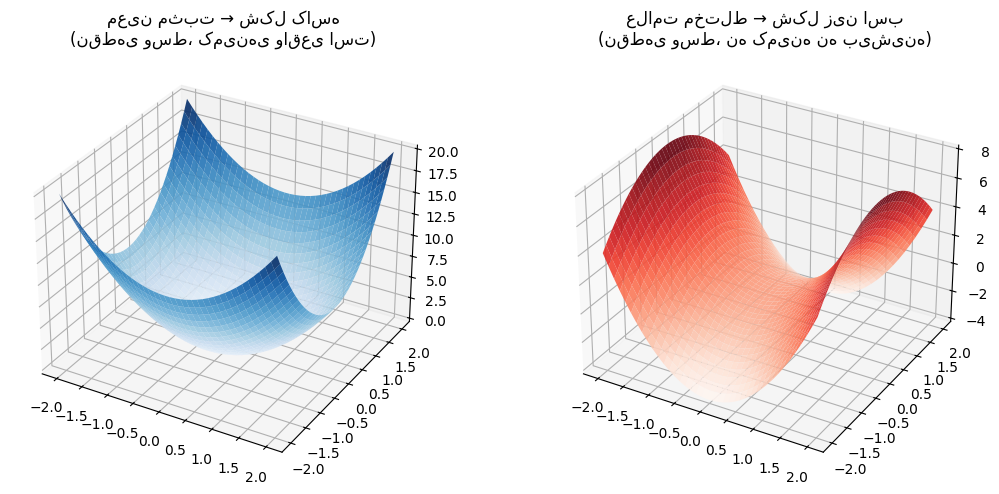

In [11]:
# تجسم دو نوع سطح: کاسه‌ای (بالا) در مقابل زین اسب (پایین)
from mpl_toolkits.mplot3d import Axes3D  # noqa

x = np.linspace(-2, 2, 40)
y = np.linspace(-2, 2, 40)
X, Y = np.meshgrid(x, y)

Z_bowl = 2*X**2 + 3*Y**2          # متناظر با A_bowl
Z_saddle = 2*X**2 - 1*Y**2        # متناظر با A_saddle

fig = plt.figure(figsize=(11, 5))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_surface(X, Y, Z_bowl, cmap="Blues", alpha=0.9)
ax1.set_title("معین مثبت → شکل کاسه\n(نقطه‌ی وسط، کمینه‌ی واقعی است)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(X, Y, Z_saddle, cmap="Reds", alpha=0.9)
ax2.set_title("علامت مختلط → شکل زین اسب\n(نقطه‌ی وسط، نه کمینه نه بیشینه)")

plt.tight_layout()
plt.show()


### 🗣️ بحث دو‌نفره — ۲ دقیقه
اگر تیم شما مدلی آموزش می‌دهد و در یک نقطه «گیر می‌کند» (نه پیشرفت می‌کند نه بدتر می‌شود)، حالا با این دانش حدس می‌زنید که ممکن است  چه اتفاقی افتاده باشد؟

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>







### ✅  مدل کجا «گیر» کرده است؟

مدل در حال آموزش، پارامترها را با قاعده‌ی $\theta \leftarrow \theta - \text{lr}\cdot\nabla L$ به‌روز می‌کند. پس اگر زیان نه کم شود نه زیاد، محتمل‌ترین توضیح این است که **گرادیان تقریباً صفر شده**، یعنی مدل به یک **نقطه‌ی بحرانی** رسیده است. اینکه این نقطه چه نوعی است را **علامت مقادیر ویژه‌ی هسین** در همان نقطه مشخص می‌کند:

| وضعیت مقادیر ویژه‌ی هسین | نوع نقطه | معنی برای مدل |
|---|---|---|
| همه مثبت | کمینه‌ی (محلی) واقعی | مدل «گیر» نکرده، به یک کف دره رسیده (ولی شاید بهترین کف ممکن نباشد) |
| بعضی مثبت، بعضی منفی | نقطه‌ی زین‌اسب | در بعضی جهت‌ها هنوز می‌شود پایین رفت، ولی گرادیان صفر است؛ محتمل‌ترین حالت «گیر کردن» واقعی |
| نزدیک صفر | ناحیه‌ی تخت (plateau) | گرادیان صفر نیست ولی خیلی کوچک است؛ پیشرفت آن‌قدر کند است که شبیه توقف دیده می‌شود |

📌 یک علت غیرریاضی هم هست: **نرخ یادگیری خیلی کوچک**. گرادیان صفر نیست، فقط قدم‌ها آن‌قدر ریزند که پیشرفت دیده نمی‌شود.

برای تشخیص، اول **اندازه‌ی گرادیان** را چاپ کنید. اگر تقریباً صفر بود، مقادیر ویژه‌ی هسین را در همان نقطه حساب کنید. بیایید این را روی همان تابع زین‌اسب `Z_saddle = 2x² − y²` امتحان کنیم؛ نقطه‌ی بحرانی آن مبدأ $(0,0)$ است.

<style>
/* =====================================================================
   persian-rtl-jupyter.css
   هدف: نمایش درست متن فارسی (راست‌به‌چپ) همراه با فرمول‌های ریاضی
   (MathJax) و کد/متن انگلیسی (چپ‌به‌راست) در سلول‌های Markdown نوت‌بوک
   جوپیتر.

   این فایل برای سه محیط پوشش داده شده:
     1) JupyterLab (کلاس‌های .jp-*)
     2) Notebook کلاسیک (کلاس‌های .text_cell_render / .rendered_html)
     3) خروجی nbconvert به HTML و VS Code Jupyter (.rendered_html)
   ===================================================================== */

/* --- 1) جهت پایه‌ی سلول‌های مارک‌داون: راست‌به‌چپ ---
   معادل عملکرد dir="rtl": direction + unicode-bidi:isolate روی کانتینر،
   و direction:rtl روی *همه‌ی* فرزندان (strong, em, li, ...) تا هیچ تگی
   (مثل **بولد**) استایل را گم نکند. */
.jp-MarkdownCell .jp-RenderedMarkdown,
.text_cell_render,
.rendered_html {
    direction: rtl;
    text-align: right;
    unicode-bidi: isolate;
    font-family: "Vazirmatn", "Vazir", "Tahoma", "IRANSans", sans-serif;
    line-height: 1.9;
}

.jp-MarkdownCell .jp-RenderedMarkdown *,
.text_cell_render *,
.rendered_html * {
    direction: rtl;
    unicode-bidi: isolate;
}

/* --- 2) فرمول‌های ریاضی: همیشه چپ‌به‌راست و مستقل از متن اطراف --- */
.jp-MarkdownCell .jp-RenderedMarkdown mjx-container,
.text_cell_render mjx-container,
.rendered_html mjx-container,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax,
.text_cell_render .MathJax,
.rendered_html .MathJax,
.jp-MarkdownCell .jp-RenderedMarkdown .MathJax_Display,
.text_cell_render .MathJax_Display,
.rendered_html .MathJax_Display {
    direction: ltr;
    unicode-bidi: isolate;               /* فرمول یک "جزیره‌ی" مستقل LTR می‌شود */
    text-align: left;
}

/* فرمول‌های نمایشی (روی خط جدا، $$...$$) وسط‌چین بمانند */
mjx-container[display="true"] {
    text-align: center !important;
}

/* --- 3) کد inline و بلوک‌های کد: چپ‌به‌راست --- */
.jp-MarkdownCell .jp-RenderedMarkdown code,
.jp-MarkdownCell .jp-RenderedMarkdown pre,
.text_cell_render code,
.text_cell_render pre,
.rendered_html code,
.rendered_html pre {
    direction: ltr;
    unicode-bidi: isolate;
    text-align: left;
    font-family: "Fira Code", "Consolas", monospace;
}

/* --- 4) لیست‌ها و جدول‌ها هم راست‌چین شوند --- */
.jp-MarkdownCell .jp-RenderedMarkdown ul,
.jp-MarkdownCell .jp-RenderedMarkdown ol,
.text_cell_render ul,
.text_cell_render ol,
.rendered_html ul,
.rendered_html ol {
    padding-right: 1.5em;
    padding-left: 0;
}

.jp-MarkdownCell .jp-RenderedMarkdown table,
.text_cell_render table,
.rendered_html table {
    direction: rtl;
}
</style>
<div dir=rtl>




## بخش ۳: کارگاه عملی — روی داده‌ی پروژه‌ی خودتان

با تیم‌تان یک ماتریس کوچک (۲×۲ یا ۳×۳) از داده‌ی پروژه‌ی خودتان بسازید — مثلاً **ماتریس کوواریانس** بین دو یا سه ویژگی عددی (مثلاً رابطه‌ی بین «قیمت» و «امتیاز» محصولات). سپس:

1. مقادیر ویژه‌ی آن را حساب کنید.
2. بررسی کنید آیا معین مثبت است یا نه (ماتریس کوواریانس همیشه باید معین مثبت یا نیمه‌معین مثبت باشد — اگر نبود، جای خطا را در محاسبه‌تان پیدا کنید!).
3. یک جمله بنویسید: بزرگ‌ترین مقدار ویژه به کدام ویژگی (یا ترکیبی از ویژگی‌ها) مربوط است؟ *(این دقیقاً هسته‌ی PCA است — جلسه ۷!)*

In [12]:

# فضای کار تیم شما 👇
# مثال: دو ستون از داده‌ی پروژه‌تان (هر سطر یک نمونه/کاربر/محصول)
feature_1 = torch.tensor([3.636802, 14.691189, 4.829448, 7.805090, 1.124621], dtype=torch.float32)  # ستون own_price
feature_2 = torch.tensor([3.448059, 12.193492, 4.719306, 1.508667, -2.952796], dtype=torch.float32) # ستون price_gap_vs_cheapest_competitor

data = torch.stack([feature_1, feature_2])
cov_matrix = torch.cov(data)
print("ماتریس کوواریانس:\n", cov_matrix)

eigvals, eigvecs = torch.linalg.eigh(cov_matrix)
print("مقادیر ویژه:", eigvals.tolist())

ماتریس کوواریانس:
 tensor([[27.1620, 25.3815],
        [25.3815, 30.5672]])
مقادیر ویژه: [3.4260263442993164, 54.303192138671875]


## جمع‌بندی و تکلیف

**تکلیف قبل از جلسه‌ی بعد:**
1. تمرین‌های `# TODO` را کامل کنید.
2. فصل مربوط به SVD از *Mathematics for Machine Learning* (فصل ۴، بخش تجزیه) را مرور کنید.

**منابع این جلسه:**
- Deisenroth et al. — *Mathematics for Machine Learning*, فصل ۴ (Matrix Decompositions)
- Strang — *Linear Algebra and Learning from Data*, فصل ۱ (Eigenvalues)
- ویدئوی 3Blue1Brown — «Eigenvectors and eigenvalues»
